Question 1: Image Preparation and Understanding

The two images show the same scene from a similar aerial viewpoint. The original color images and their grayscale versions are displayed above.

Grayscale is commonly used before feature detection because keypoint algorithms mainly use structural information such as edges, corners, textures, and intensity changes. Using one channel instead of three color channels reduces computation and makes detection less affected by color or lighting changes.

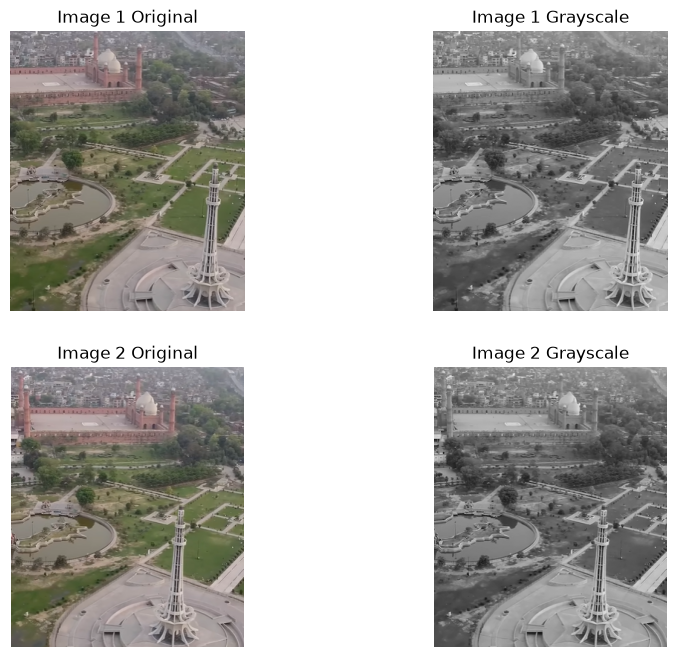

In [4]:
import cv2
import matplotlib.pyplot as plt

img1_color = cv2.imread(r'D:\ComputerVision\m3.png')
img2_color = cv2.imread(r'D:\ComputerVision\m4.png')

img1_rgb = cv2.cvtColor(img1_color, cv2.COLOR_BGR2RGB)
img2_rgb = cv2.cvtColor(img2_color, cv2.COLOR_BGR2RGB)

img1_gray = cv2.cvtColor(img1_color, cv2.COLOR_BGR2GRAY)
img2_gray = cv2.cvtColor(img2_color, cv2.COLOR_BGR2GRAY)

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
axes[0, 0].imshow(img1_rgb); axes[0, 0].set_title('Image 1 Original')
axes[0, 1].imshow(img1_gray, cmap='gray'); axes[0, 1].set_title('Image 1 Grayscale')
axes[1, 0].imshow(img2_rgb); axes[1, 0].set_title('Image 2 Original')
axes[1, 1].imshow(img2_gray, cmap='gray'); axes[1, 1].set_title('Image 2 Grayscale')
for ax in axes.flat: ax.axis('off')
plt.show()

Question 2: ORB Keypoints and Descriptors

ORB detected 487 keypoints in Image 1 and 492 keypoints in Image 2.

A keypoint is a distinctive image location, such as a corner, edge, or textured detail. A descriptor is a binary numerical representation of the area around a keypoint, allowing the same feature to be recognized in another image. Most keypoints appear around the mosque, garden paths, circular pool, trees, and the foreground monument because these areas contain strong edges, corners, and texture. Smooth sky and plain surfaces contain fewer keypoints.

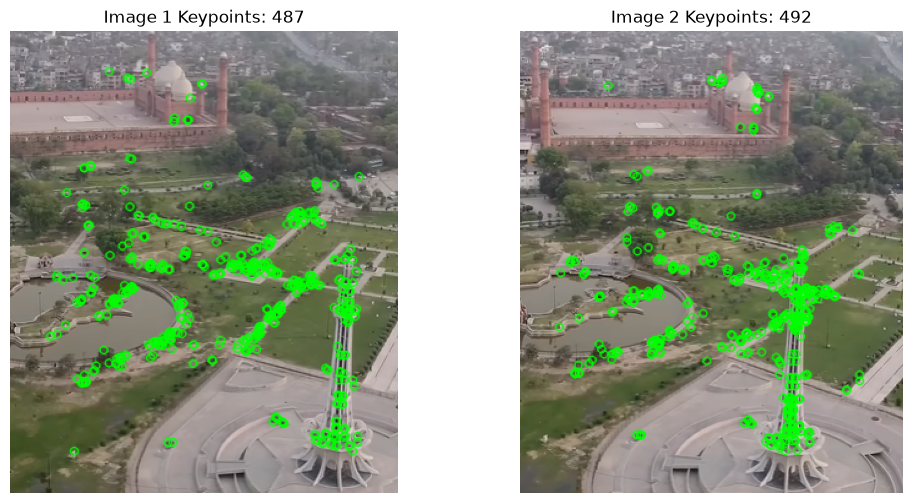

Number of keypoints in Image 1: 487
Number of keypoints in Image 2: 492


In [8]:
orb = cv2.ORB_create()

keypoints1, descriptors1 = orb.detectAndCompute(img1_gray, None)
keypoints2, descriptors2 = orb.detectAndCompute(img2_gray, None)

img1_kp = cv2.drawKeypoints(img1_rgb, keypoints1, None, color=(0, 255, 0), flags=0)
img2_kp = cv2.drawKeypoints(img2_rgb, keypoints2, None, color=(0, 255, 0), flags=0)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(img1_kp); axes[0].set_title(f'Image 1 Keypoints: {len(keypoints1)}')
axes[1].imshow(img2_kp); axes[1].set_title(f'Image 2 Keypoints: {len(keypoints2)}')
for ax in axes: ax.axis('off')
plt.show()

print(f'Number of keypoints in Image 1: {len(keypoints1)}')
print(f'Number of keypoints in Image 2: {len(keypoints2)}')

Question 3: Feature Matching

ORB descriptors were matched using a brute-force matcher with Hamming distance, which is appropriate for ORB's binary descriptors. The 50 best matches are displayed above.

Examples of good matches include corresponding points on the mosque roof and dome, matching edges along the garden paths, and matching details around the circular pool and foreground monument. These lines connect similar physical structures in both images. A weak match is a line that connects a small tree or garden texture in one image to a different path or building edge in the other image. This is incorrect because the two regions only have similar local edge patterns, not the same physical location.

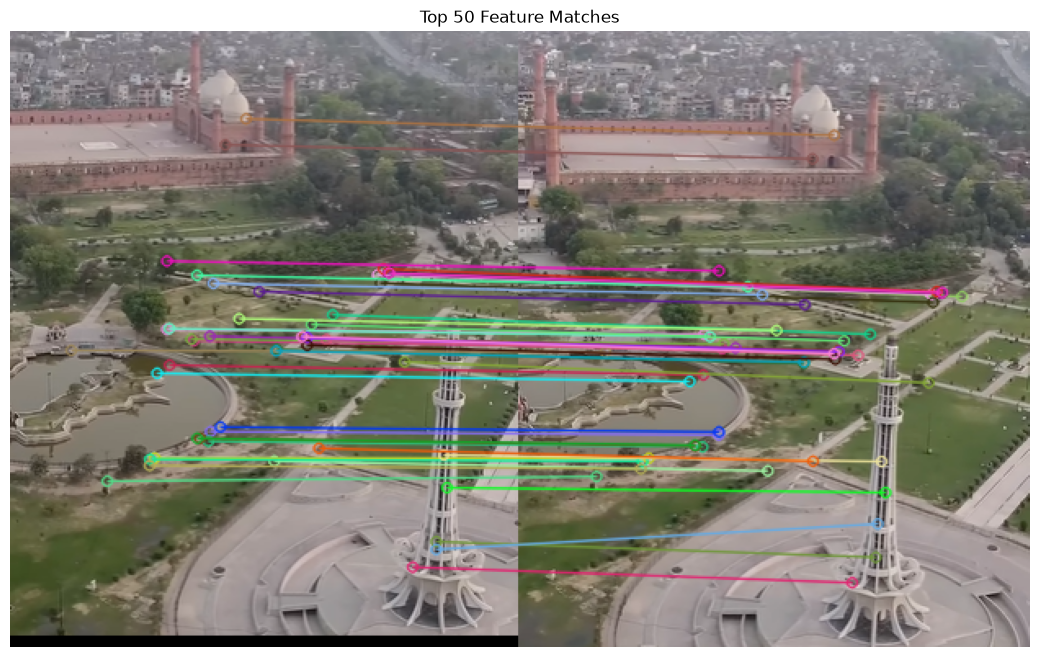

In [9]:
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)

matches = bf.match(descriptors1, descriptors2)
matches = sorted(matches, key=lambda x: x.distance)

img_matches = cv2.drawMatches(img1_rgb, keypoints1, img2_rgb, keypoints2, matches[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 8))
plt.imshow(img_matches)
plt.title('Top 50 Feature Matches')
plt.axis('off')
plt.show()

Question 4: Experiment and Comparison

Image 2 was rotated by 45 degrees and ORB detection and matching were repeated. The original pair produced 203 matches, while the rotated pair produced 190 matches.

The number of matches decreased slightly after rotation, but many corresponding features were still found. The rotated result also contains more widely spread and less visually aligned lines because the image orientation changed and some areas moved outside the frame. This shows that ORB provides useful rotation resistance, although rotation can reduce match quantity and quality.

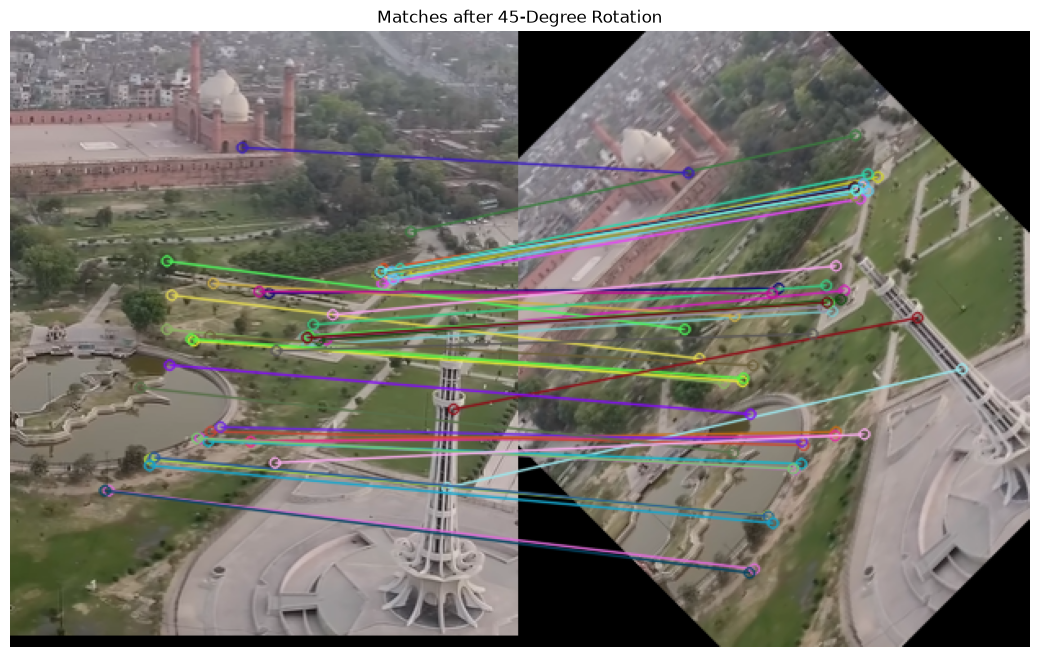

Original Matches: 203 | Matches after rotation: 190


In [11]:
(h, w) = img2_gray.shape[:2]
center = (w // 2, h // 2)
M = cv2.getRotationMatrix2D(center, 45, 1.0)
img2_rotated = cv2.warpAffine(img2_gray, M, (w, h))

keypoints2_rot, descriptors2_rot = orb.detectAndCompute(img2_rotated, None)
matches_rot = bf.match(descriptors1, descriptors2_rot)
matches_rot = sorted(matches_rot, key=lambda x: x.distance)

img2_rot_rgb = cv2.cvtColor(cv2.warpAffine(img2_color, M, (w, h)), cv2.COLOR_BGR2RGB)
img_matches_rot = cv2.drawMatches(img1_rgb, keypoints1, img2_rot_rgb, keypoints2_rot, matches_rot[:50], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(15, 8))
plt.imshow(img_matches_rot)
plt.title('Matches after 45-Degree Rotation')
plt.axis('off')
plt.show()

print(f'Original Matches: {len(matches)} | Matches after rotation: {len(matches_rot)}')